In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
df = pd.read_csv('winemag-data_first150k.csv')
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150930 entries, 0 to 150929
Data columns (total 11 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Unnamed: 0   150930 non-null  int64  
 1   country      150925 non-null  object 
 2   description  150930 non-null  object 
 3   designation  105195 non-null  object 
 4   points       150930 non-null  int64  
 5   price        137235 non-null  float64
 6   province     150925 non-null  object 
 7   region_1     125870 non-null  object 
 8   region_2     60953 non-null   object 
 9   variety      150930 non-null  object 
 10  winery       150930 non-null  object 
dtypes: float64(1), int64(2), object(8)
memory usage: 12.7+ MB
None
          Unnamed: 0         points          price
count  150930.000000  150930.000000  137235.000000
mean    75464.500000      87.888418      33.131482
std     43569.882402       3.222392      36.322536
min         0.000000      80.000000       4.000000
25%    

In [4]:
print(df.head)

<bound method NDFrame.head of         Unnamed: 0 country                                        description  \
0                0      US  This tremendous 100% varietal wine hails from ...   
1                1   Spain  Ripe aromas of fig, blackberry and cassis are ...   
2                2      US  Mac Watson honors the memory of a wine once ma...   
3                3      US  This spent 20 months in 30% new French oak, an...   
4                4  France  This is the top wine from La Bégude, named aft...   
...            ...     ...                                                ...   
150925      150925   Italy  Many people feel Fiano represents southern Ita...   
150926      150926  France  Offers an intriguing nose with ginger, lime an...   
150927      150927   Italy  This classic example comes from a cru vineyard...   
150928      150928  France  A perfect salmon shade, with scents of peaches...   
150929      150929   Italy  More Pinot Grigios should taste like this. A r...  

In [5]:
# 2. Verificar nulos por columna
print("Valores nulos por columna:")
print(df.isnull().sum())

Valores nulos por columna:
Unnamed: 0         0
country            5
description        0
designation    45735
points             0
price          13695
province           5
region_1       25060
region_2       89977
variety            0
winery             0
dtype: int64


In [6]:
#identificar nulos de Driver_Name
nulos = df['designation'].isnull().sum()
nulos_porcentaje= df['designation'].isnull().mean()* 100
print(f"Valores nulos en designation: {nulos} ({nulos_porcentaje:.2f}%)")
nulos_1 = df['price'].isnull().sum()
nulos_porcentaje1= df['price'].isnull().mean()* 100
print(f"Valores nulos en price: {nulos_1} ({nulos_porcentaje1:.2f}%)")
nulos2 = df['province'].isnull().sum()
nulos_porcentaje2= df['province'].isnull().mean()* 100
print(f"Valores nulos en province: {nulos2} ({nulos_porcentaje2:.2f}%)")
nulos3 = df['region_1'].isnull().sum()
nulos_porcentaje3= df['region_1'].isnull().mean()* 100
print(f"Valores nulos en region_1: {nulos3} ({nulos_porcentaje3:.2f}%)")
nulos4 = df['region_2'].isnull().sum()
nulos_porcentaje4= df['region_2'].isnull().mean()* 100
print(f"Valores nulos en region_2: {nulos4} ({nulos_porcentaje4:.2f}%)")

Valores nulos en designation: 45735 (30.30%)
Valores nulos en price: 13695 (9.07%)
Valores nulos en province: 5 (0.00%)
Valores nulos en region_1: 25060 (16.60%)
Valores nulos en region_2: 89977 (59.62%)


In [7]:
# Rellena los precios faltantes usando el promedio de cada cepa ('variety')
df['price'] = df['price'].fillna(df.groupby('variety')['price'].transform('mean'))

# Si aún queda algún nulo (ej. una cepa donde ningún vino tenía precio), se rellena con el promedio general
df['price'] = df['price'].fillna(df['price'].mean())

In [ ]:

# 2. Variables numéricas
# Rellenar precio utilizando la mediana por variedad de vino
df["price"] = df["price"].fillna(
    df.groupby("variety")["price"].transform("median")
)

# Si todavía quedan valores nulos, utilizar la mediana general
df["price"] = df["price"].fillna(df["price"].median())


# 3. Variables categóricas con pocos valores faltantes
# Utilizar la moda (valor más frecuente)

columnas_moda = ["country", "province"]

for columna in columnas_moda:
    df[columna] = df[columna].fillna(df[columna].mode()[0])


# 4. Variables categóricas con muchos valores faltantes
# No inventar regiones o denominaciones

columnas_categoria = [
    "designation",
    "region_1",
    "region_2"
]

for columna in columnas_categoria:
    df[columna] = df[columna].fillna("No especificado")


# 5. Comprobar resultados
print("\nDatos faltantes después:")
print(df.isnull().sum())

# 6. Guardar dataset limpio
#df.to_csv("winemag-data_limpio.csv", index=False)

print("\nDataset limpio guardado correctamente.")



Datos faltantes después:
Unnamed: 0     0
country        0
description    0
designation    0
points         0
price          0
province       0
region_1       0
region_2       0
variety        0
winery         0
dtype: int64

Dataset limpio guardado correctamente.


              points          price
count  150930.000000  150930.000000
mean       87.888418      33.543125
std         3.222392      34.947729
min        80.000000       4.000000
25%        86.000000      16.000000
50%        88.000000      25.000000
75%        90.000000      40.000000
max       100.000000    2300.000000


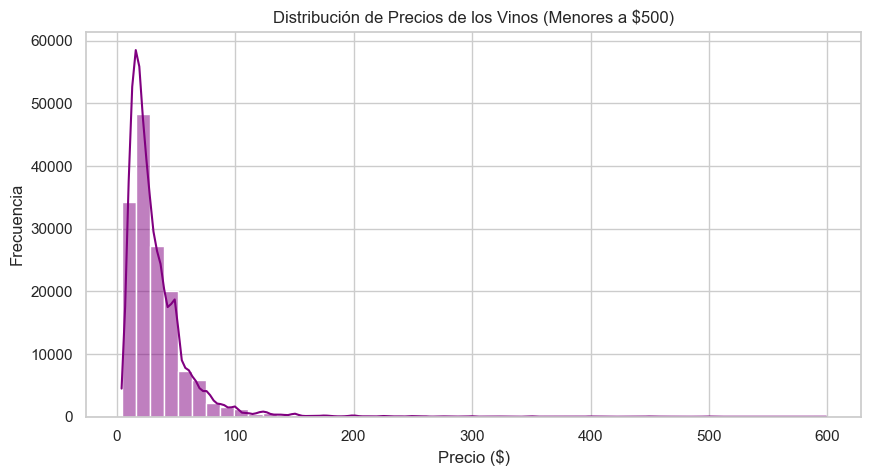

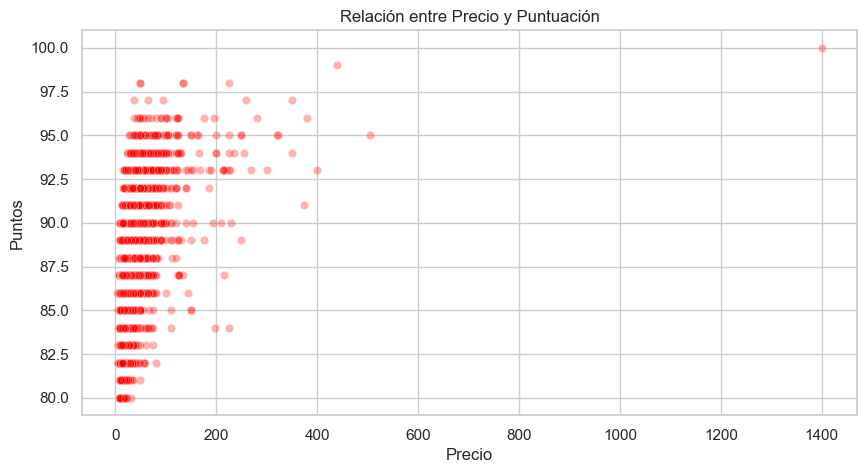

In [8]:
# Configuración visual básica
sns.set_theme(style="whitegrid")

# 1. Estadísticas descriptivas de precio y puntos
print(df[['points', 'price']].describe())

# 2. Gráfico de distribución de precios (filtrando valores extremos para mejor visualización)
plt.figure(figsize=(10, 5))
sns.histplot(df[df['price'] < 600]['price'], bins=50, kde=True, color='purple')
plt.title('Distribución de Precios de los Vinos (Menores a $500)')
plt.xlabel('Precio ($)')
plt.ylabel('Frecuencia')
plt.show()

# 3. Relación entre Puntos y Precio (Muestreo para agilizar el gráfico)
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df.sample(5000, random_state=42), x='price', y='points', alpha=0.3, color='red')
plt.title('Relación entre Precio y Puntuación')
plt.xlabel('Precio')
plt.ylabel('Puntos')
plt.show()

In [11]:
#contar cantidad total de vinos 
vinos_total = len(df)
print(f"Cantidad total de vinos en el dataset: {vinos_total}")

Cantidad total de vinos en el dataset: 150930


In [12]:
#vinos unicos
vinos_unicos = df['description'].nunique()
print(f"Cantidad de descripciones únicas de vinos: {vinos_unicos}")

Cantidad de descripciones únicas de vinos: 97821


In [ ]:
#variedad de vinos
vinos_por_variedad = df["variety"].value_counts()

print(vinos_por_variedad.head(10))

variety
Chardonnay                  14482
Pinot Noir                  14291
Cabernet Sauvignon          12800
Red Blend                   10062
Bordeaux-style Red Blend     7347
Sauvignon Blanc              6320
Syrah                        5825
Riesling                     5524
Merlot                       5070
Zinfandel                    3799
Name: count, dtype: int64


In [15]:
#que bodegas tienen mas vinos registrados
vino_por_bodega = df["winery"].value_counts()
print(vino_por_bodega.head(10))

winery
Williams Selyem          374
Testarossa               274
DFJ Vinhos               258
Chateau Ste. Michelle    225
Columbia Crest           217
Kendall-Jackson          216
Concha y Toro            216
Trapiche                 205
Bouchard Père & Fils     203
Kenwood                  191
Name: count, dtype: int64


In [ ]:
#